# 02 — Data Preprocessing
**Project:** California Property Close Price Prediction (IDX Exchange, team ds76)
**Week 3 deliverable:** handle missing values, encode categoricals, scale numerics, and build a time-based train/test split with a tuned training window (X months).

Same scope as Week 2: `PropertyType == "Residential"` and `PropertySubType == "SingleFamilyResidence"`, target **`ClosePrice`**.

Two kinds of steps:
* **Cleaning (sections 1–3):** fixed rules written in pandas, run on every month at once.
* **Imputation, encoding, scaling (sections 4–5):** these *learn* values from the data (a median, a ZIP's average price), so they are **fit on the training months only**. Otherwise the test month would leak into training.

In [1]:
import glob
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler, TargetEncoder

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. Load all months
Week 2 used Oct 2025 – May 2026. The folder now has **Jan 2024 – May 2026**, so we can test longer training windows in section 5.
* **Aug and Sep 2025 are missing.**
* The `*_filled.csv` files already had missing coordinates filled in. Their two extra flag columns (`latfilled`, `lonfilled`) aren't used.

In [2]:
files = sorted(glob.glob("CRMLSSold*.csv"))
frames = []
for f in files:
    d = pd.read_csv(f, low_memory=False)
    d["SourceMonth"] = re.search(r"\d{6}", f).group()   # e.g. 202401, works for *_filled.csv too
    frames.append(d)

raw = pd.concat(frames, ignore_index=True)
print(f"{len(files)} files, {raw.shape[0]:,} rows, {raw.shape[1]} columns")

27 files, 591,028 rows, 83 columns


In [3]:
raw.groupby("SourceMonth").size().rename("rows").to_frame().T

SourceMonth,202401,202402,202403,202404,202405,202406,202407,202408,202409,202410,202411,202412,202501,202502,202503,202504,202505,202506,202507,202510,202511,202512,202601,202602,202603,202604,202605
rows,17958,19925,23276,24640,26487,24328,26240,24558,21267,23274,20279,20241,18738,18702,21445,23262,23154,22883,23646,23233,19088,20538,16487,18124,22583,23412,23260


## 2. Cleaning
### 2.1 Keep single-family homes only
The raw files include condos, townhomes, land, and rentals. This project only predicts single-family home prices.

In [4]:
print(raw["PropertyType"].value_counts().head(), "\n")

df = raw[(raw["PropertyType"] == "Residential") &
         (raw["PropertySubType"] == "SingleFamilyResidence")].copy()
print(f"Single-family sales: {len(df):,}")

PropertyType
Residential           397771
ResidentialLease      134890
Land                   19298
ManufacturedInPark     16049
ResidentialIncome      15831
Name: count, dtype: int64 



Single-family sales: 297,596


### 2.2 Remove duplicate listings
Some listings appear in two monthly files. Counting a sale twice gives it extra weight, so we keep the latest record.

In [5]:
print("Duplicate ListingKeys:", df["ListingKey"].duplicated().sum())

df = df.sort_values("SourceMonth", kind="stable").drop_duplicates("ListingKey", keep="last")
print(f"After removing duplicates: {len(df):,}")

Duplicate ListingKeys: 255


After removing duplicates: 297,341


### 2.3 Drop sales with impossible price or size
Week 2 found entry errors like a \$1.75 sale and a \$989.5M sale. We keep sales between \$50K and \$30M, 300 to 20,000 sq ft, and \$25 to \$5,000 per sq ft.

In [6]:
df["CloseDate"] = pd.to_datetime(df["CloseDate"], errors="coerce")
price_per_sqft = df["ClosePrice"] / df["LivingArea"]

keep = (df["CloseDate"].notna()
        & df["ClosePrice"].between(50_000, 30_000_000)
        & df["LivingArea"].between(300, 20_000)
        & price_per_sqft.between(25, 5_000))

print(f"Removing {(~keep).sum():,} sales ({(~keep).mean():.2%})")
df.loc[~keep, ["ClosePrice", "LivingArea"]].assign(PricePerSqFt=price_per_sqft).sort_values("ClosePrice").head(8)

Removing 546 sales (0.18%)


,ClosePrice,LivingArea,PricePerSqFt
407174,0.000,"2,001.000",0.000
270587,1.150,"1,811.000",0.001
497753,1.750,"3,513.000",0.000
108697,345.000,"2,048.000",0.168
203942,380.000,"1,200.000",0.317
434633,485.000,"1,305.000",0.372
561959,685.000,"2,980.000",0.230
514453,"8,000.000",984.000,8.130


In [7]:
df = df[keep]
print(f"Sales left: {len(df):,}")

Sales left: 296,795


### 2.4 Blank out impossible values instead of deleting the sale
Examples include 0 or 175 bathrooms, a 600-car garage, negative parking, and coordinates outside California. One wrong field doesn't make the whole sale useless, so we set only that value to blank (NaN). The pipeline in section 5 fills it in.

In [8]:
before = df.isna().sum()

df.loc[~df["BedroomsTotal"].between(1, 15), "BedroomsTotal"] = np.nan
df.loc[~df["BathroomsTotalInteger"].between(1, 15), "BathroomsTotalInteger"] = np.nan
df.loc[~df["YearBuilt"].between(1850, df["CloseDate"].dt.year + 2), "YearBuilt"] = np.nan
df.loc[df["LotSizeSquareFeet"] <= 0, "LotSizeSquareFeet"] = np.nan
df.loc[~df["GarageSpaces"].between(0, 20), "GarageSpaces"] = np.nan
df.loc[~df["ParkingTotal"].between(0, 50), "ParkingTotal"] = np.nan
df.loc[df["MainLevelBedrooms"] > df["BedroomsTotal"], "MainLevelBedrooms"] = np.nan

in_ca = df["Latitude"].between(32.4, 42.1) & df["Longitude"].between(-124.5, -114.1)
df.loc[~in_ca, ["Latitude", "Longitude"]] = np.nan

blanked = df.isna().sum() - before
blanked[blanked > 0].to_frame("values blanked")

,values blanked
Latitude,77
Longitude,77
ParkingTotal,229
YearBuilt,6
BathroomsTotalInteger,85
BedroomsTotal,117
MainLevelBedrooms,1765
GarageSpaces,50
LotSizeSquareFeet,149


### 2.5 Tidy text columns, fill coordinates from the ZIP
* ZIP codes like `92126-1234` become `92126`.
* `Levels` values like "One,Two" keep the first value.
* Blank text becomes its own **"Missing"** category.
* Missing coordinates get the median coordinates of the same ZIP. This only uses location, not price, so it can't leak.

In [9]:
df["PostalCode"] = df["PostalCode"].astype(str).str[:5]
df["Levels"] = df["Levels"].str.split(",").str[0]

for col in ["CountyOrParish", "Levels", "City", "PostalCode", "MLSAreaMajor", "HighSchoolDistrict"]:
    df[col] = df[col].fillna("Missing").astype(str)

print("Missing coordinates before:", df["Latitude"].isna().sum())
for col in ["Latitude", "Longitude"]:
    df[col] = df[col].fillna(df.groupby("PostalCode")[col].transform("median"))
print("Missing coordinates after: ", df["Latitude"].isna().sum())

Missing coordinates before: 2582
Missing coordinates after:  19


### 2.6 Put HOA fees on one monthly scale
Fees are billed monthly, quarterly, semi-annually, or annually, so we convert them all to a monthly amount. No fee listed means no HOA (0). A fee with no frequency is treated as monthly.

In [10]:
print(df["AssociationFeeFrequency"].value_counts(dropna=False), "\n")

per_month = {"Monthly": 1, "Quarterly": 1/3, "SemiAnnually": 1/6, "Annually": 1/12}
factor = df["AssociationFeeFrequency"].map(per_month).fillna(1)
df["AssociationFeeMonthly"] = (df["AssociationFee"] * factor).fillna(0)

df["AssociationFeeMonthly"].describe()

AssociationFeeFrequency
NaN             222042
Monthly          65504
Annually          6072
Quarterly         2793
SemiAnnually       384
Name: count, dtype: int64 



count   296,795.000
mean         54.482
std         143.237
min           0.000
25%           0.000
50%           0.000
75%           6.667
max      12,400.000
Name: AssociationFeeMonthly, dtype: float64

### 2.7 Yes/no columns → 1/0, flooring text → yes/no columns
`Flooring` is a text list like "Tile,Carpet,Wood". We split it into one 0/1 column for each common material (each in at least 2% of listings).

In [11]:
yes_no = ["ViewYN", "PoolPrivateYN", "FireplaceYN", "AttachedGarageYN", "NewConstructionYN"]
for col in yes_no:
    df[col] = df[col].astype(float)        # True/False/blank -> 1/0/NaN

print(df["Flooring"].value_counts().head(5), "\n")

floor_types = ["Tile", "Carpet", "Wood", "Laminate", "Vinyl", "Stone"]
floors = df["Flooring"].fillna("").str.get_dummies(sep=",")
for t in floor_types:
    df[f"Floor_{t}"] = floors[t]

df[[f"Floor_{t}" for t in floor_types]].mean().rename("share of homes").to_frame()

Flooring
Carpet,Tile         21126
Wood                18990
Tile,Wood           16496
Laminate            14461
Carpet,Tile,Wood    11989
Name: count, dtype: int64 



,share of homes
Floor_Tile,0.324
Floor_Carpet,0.300
Floor_Wood,0.254
Floor_Laminate,0.179
Floor_Vinyl,0.107
Floor_Stone,0.029


## 3. Choose the columns the model can use
| Group | Columns | Reason dropped |
|---|---|---|
| **Leakage** | ListPrice, OriginalListPrice, DaysOnMarket, ListingContractDate, PurchaseContractDate, ContractStatusChangeDate | Only known once a home is listed or sold. We want to price *any* home, including ones not for sale. ListPrice has ρ = 0.99 with ClosePrice (Week 2) |
| IDs & addresses | ListingId, ListingKeyNumeric, UnparsedAddress, StreetNumberNumeric | Not about the home (ListingKey and CloseDate are kept only for bookkeeping and the split) |
| Agents & offices | ListAgent\*, CoListAgent\*, BuyerAgent\*, \*OfficeName, \*AOR, BuyerAgencyCompensation\* | Describe who sold the home, not the home |
| Over 90% empty | TaxAnnualAmount, TaxYear, WaterfrontYN, BasementYN, BuilderName, FireplacesTotal, … | Too little data |
| Redundant | LotSizeAcres, LotSizeArea | Same as LotSizeSquareFeet |
| Too sparse or too many levels | School names (>80% missing), SubdivisionName (65% missing) | Week 6 adds school districts from the shapefile |

**ClosePrice stays.** It is the **target**, the answer the model learns to predict, not an input.

In [12]:
TARGET = "ClosePrice"
SKEWED = ["LivingArea", "LotSizeSquareFeet", "AssociationFeeMonthly"]       # log1p before scaling
NUMERIC = ["BedroomsTotal", "BathroomsTotalInteger", "YearBuilt", "GarageSpaces", "ParkingTotal",
           "Stories", "MainLevelBedrooms", "Latitude", "Longitude"]
BINARY = yes_no
LOW_CARD = ["CountyOrParish", "Levels"]                                       # one-hot
HIGH_CARD = ["City", "PostalCode", "MLSAreaMajor", "HighSchoolDistrict"]      # target-encoded
FLOORING = [f"Floor_{t}" for t in floor_types]
FEATURES = SKEWED + NUMERIC + BINARY + LOW_CARD + HIGH_CARD + FLOORING

df = df[["ListingKey", "CloseDate", TARGET] + FEATURES].reset_index(drop=True)
dropped = [c for c in raw.columns if c not in df.columns]

print(f"Kept {len(FEATURES)} features. Dropped {len(dropped)} raw columns.")
print(f"Clean dataset: {df.shape[0]:,} sales x {df.shape[1]} columns")
df.head()

Kept 29 features. Dropped 58 raw columns.
Clean dataset: 296,795 sales x 32 columns


,ListingKey,CloseDate,ClosePrice,LivingArea,LotSizeSquareFeet,AssociationFeeMonthly,BedroomsTotal,BathroomsTotalInteger,YearBuilt,GarageSpaces,ParkingTotal,Stories,MainLevelBedrooms,Latitude,Longitude,ViewYN,PoolPrivateYN,FireplaceYN,AttachedGarageYN,NewConstructionYN,CountyOrParish,Levels,City,PostalCode,MLSAreaMajor,HighSchoolDistrict,Floor_Tile,Floor_Carpet,Floor_Wood,Floor_Laminate,Floor_Vinyl,Floor_Stone
0,522107581,2024-01-05,"815,000.000","1,974.000",NaN,0.000,4.000,4.000,"2,023.000",2.000,2.000,2.000,NaN,32.659,-117.097,0.000,0.000,0.000,1.000,0.000,San Diego,Two,National City,91950,91950 - National City,Missing,0,0,0,0,0,0
1,510919001,2024-01-05,"810,000.000","1,974.000",NaN,0.000,4.000,4.000,"2,023.000",2.000,2.000,2.000,NaN,32.659,-117.097,0.000,0.000,0.000,1.000,0.000,San Diego,Two,National City,91950,91950 - National City,Missing,0,0,0,0,0,0
2,1067652762,2024-01-02,"2,100,000.000","3,736.000","11,219.000",0.000,4.000,4.000,"2,019.000",3.000,3.000,2.000,3.000,35.277,-120.647,1.000,0.000,1.000,1.000,0.000,San Luis Obispo,Two,San Luis Obispo,93401,SLO - San Luis Obispo,San Luis Coastal Unified,0,0,0,0,0,0
3,1063453216,2024-01-22,"1,950,000.000","2,100.000","74,487.600",0.000,3.000,NaN,"1,986.000",2.000,2.000,2.000,NaN,39.419,-123.815,1.000,0.000,1.000,1.000,NaN,Mendocino,Two,Fort Bragg,95437,FBS - Fort Bragg South,Missing,1,0,0,0,0,0
4,1061988701,2024-01-31,"2,340,000.000","2,442.000","8,712.000",0.000,4.000,3.000,"1,985.000",3.000,3.000,NaN,NaN,37.325,-121.780,1.000,NaN,1.000,1.000,0.000,Santa Clara,Missing,San Jose,95148,699 - Not Defined,Other,1,0,1,0,0,0


## 4. Missing values: drop, impute, or flag?

In [13]:
missing = (df[FEATURES].isna().mean() * 100).round(1)
missing = missing[missing > 0].sort_values(ascending=False).to_frame("% missing")
missing["decision"] = np.where(missing.index.isin(BINARY),
                               "fill 0 (= not listed) + missing flag",
                               "median + missing flag")
missing

,% missing,decision
MainLevelBedrooms,41.000,median + missing flag
Stories,12.900,median + missing flag
AttachedGarageYN,11.500,fill 0 (= not listed) + missing flag
PoolPrivateYN,9.700,fill 0 (= not listed) + missing flag
ViewYN,8.900,fill 0 (= not listed) + missing flag
NewConstructionYN,7.200,fill 0 (= not listed) + missing flag
GarageSpaces,3.600,median + missing flag
LotSizeSquareFeet,1.800,median + missing flag
ParkingTotal,0.200,median + missing flag
YearBuilt,0.100,median + missing flag


**Decisions**
* **No more rows are dropped.** The target, LivingArea, beds, baths, and location are almost fully filled in.
* **Numbers → median, plus a 0/1 "was missing" flag.** The median isn't pulled around by Week 2's outliers. The flag lets the model learn whether "missing" means something. For example, MainLevelBedrooms is 41% missing, which is too much to drop.
* **Yes/no → 0, plus a flag.** A blank pool or view field usually means the agent didn't tick it.
* **Text → "Missing" category** (done in 2.5).
* The medians are learned **from the training months only**. That happens in the pipeline in section 5.

## 5. Encoding and scaling
### Categories → numbers
Models only understand numbers.
* **County (about 60 values) and Levels → one-hot:** one 0/1 column per value.
* **City, ZIP, MLS area, and high-school district have hundreds to thousands of values.** One-hot would create about 4,000 mostly empty columns. Instead we use **target encoding**: each ZIP becomes the average log price of that ZIP, computed from training data only and cross-fitted so a home never uses its own price.

In [14]:
df[LOW_CARD + HIGH_CARD].nunique().rename("distinct values").to_frame()

,distinct values
CountyOrParish,63
Levels,5
City,1105
PostalCode,1576
MLSAreaMajor,1070
HighSchoolDistrict,441


In [15]:
# One-hot example: one 0/1 column per value
pd.get_dummies(df["Levels"]).astype(int).head()

,Missing,MultiSplit,One,ThreeOrMore,Two
0,0,0,0,0,1
1,0,0,0,0,1
2,0,0,0,0,1
3,0,0,0,0,1
4,1,0,0,0,0


In [16]:
# Target encoding idea: each ZIP replaced by how expensive that ZIP is
df.groupby("PostalCode")["ClosePrice"].agg(sales="size", median_price="median").query("sales >= 100").sort_values("median_price").iloc[[0, 1, 2, -3, -2, -1]]

,sales,median_price
PostalCode,,
92225,198,"240,000.000"
95422,227,"249,000.000"
95423,108,"265,000.000"
92661,111,"6,299,000.000"
92657,158,"7,550,000.000"
94027,111,"7,800,000.000"


### Scaling
* **Skewed sizes (living area, lot size, HOA) → log.** Lot size goes up to 2 billion sq ft, and the log squashes those huge values.
* **All numeric columns → standardized** (mean 0, sd 1). Linear Regression (Week 4) needs this. Tree models don't care, but it doesn't hurt them.
* **The price is modeled on a log scale too,** then converted back to dollars for R².

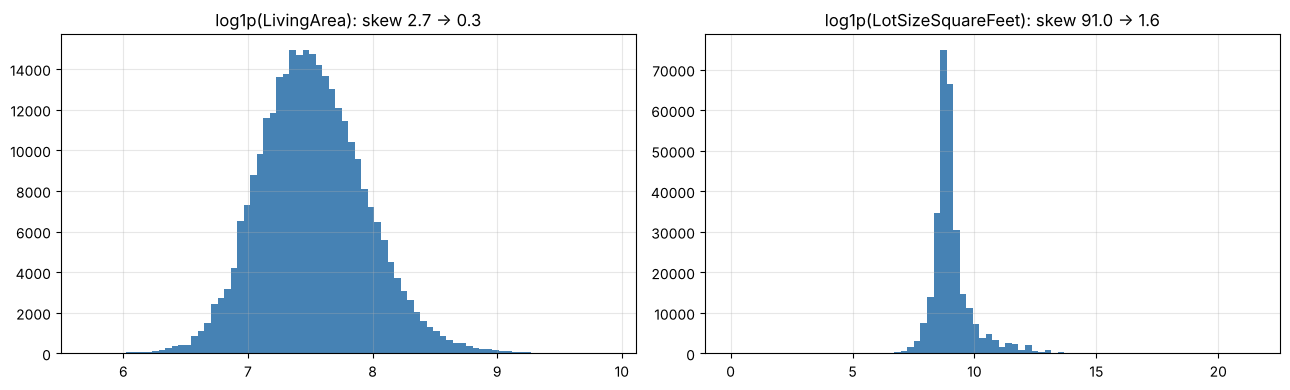

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["LivingArea", "LotSizeSquareFeet"]):
    s = df[col].dropna()
    ax.hist(np.log1p(s), bins=80, color="steelblue")
    ax.set_title(f"log1p({col}): skew {s.skew():.1f} → {np.log1p(s).skew():.1f}")
plt.tight_layout(); plt.show()

### Putting it together
These steps go into one scikit-learn pipeline. It learns every median, ZIP average, and scaling factor **from the training data only**, then applies them to the test data.

In [18]:
def build_preprocessor():
    return ColumnTransformer([
        ("skewed",   make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                                   SimpleImputer(strategy="median", add_indicator=True),
                                   StandardScaler()), SKEWED),
        ("numeric",  make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                                   StandardScaler()), NUMERIC),
        ("binary",   SimpleImputer(strategy="constant", fill_value=0, add_indicator=True), BINARY),
        ("onehot",   OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50,
                                   sparse_output=False), LOW_CARD),
        ("target",   make_pipeline(TargetEncoder(target_type="continuous", random_state=0),
                                   StandardScaler()), HIGH_CARD),
        ("flooring", "passthrough", FLOORING),
    ], verbose_feature_names_out=False)


def price_model(model):
    # learn on log(price), predict back in dollars
    return TransformedTargetRegressor(make_pipeline(build_preprocessor(), model),
                                      func=np.log, inverse_func=np.exp)


def time_split(df, test_month, months_back):
    month = df["CloseDate"].dt.to_period("M")
    test_month = pd.Period(test_month, "M")
    train = df[(month >= test_month - months_back) & (month < test_month)]
    test = df[month == test_month]
    return train, test

In [19]:
# Check: fit on 6 example months, apply to May 2026
train, test = time_split(df, "2026-05", 6)
prep = build_preprocessor().set_output(transform="pandas")
X_train = prep.fit_transform(train[FEATURES], np.log(train[TARGET]))
X_test = prep.transform(test[FEATURES])

assert X_train.notna().all().all() and X_test.notna().all().all(), "blanks left after preprocessing"
print(f"train {X_train.shape}, test {X_test.shape}: no missing values")
X_train.describe().T[["mean", "std", "min", "max"]].head(10)

train (59280, 80), test (12000, 80): no missing values


,mean,std,min,max
LivingArea,0.000,1.000,-4.117,5.184
LotSizeSquareFeet,0.000,1.000,-8.706,11.857
AssociationFeeMonthly,-0.000,1.000,-0.581,3.199
missingindicator_LotSizeSquareFeet,-0.000,1.000,-0.135,7.415
BedroomsTotal,-0.000,1.000,-2.599,11.989
BathroomsTotalInteger,0.000,1.000,-1.461,10.156
YearBuilt,0.000,1.000,-4.415,1.796
GarageSpaces,0.000,1.000,-2.212,20.163
ParkingTotal,0.000,1.000,-1.270,21.824
Stories,-0.000,1.000,-0.677,1.477


## 6. Train/test split: most recent month = test
* **Test:** May 2026, the latest month.
* **Train:** the **X** months right before it.

Split by time, not randomly. In real life we'll always use past sales to price future ones, so we test the model the same way.

### Choosing X without peeking at the test month
1. Use **April 2026 as a practice test month**, train on the X months before it, and try X = 1 to 24.
2. Pick X there, then test **once** on May 2026.

Two quick models are used as a check: Linear Regression (next week's baseline) and gradient-boosted trees.

In [20]:
results = []
for X in [1, 2, 3, 4, 6, 9, 12, 18, 24]:
    train, practice = time_split(df, "2026-04", X)
    assert train["CloseDate"].max() < practice["CloseDate"].min()     # no future data in training
    for name, model in [("LinearRegression", LinearRegression()),
                        ("HistGradientBoosting", HistGradientBoostingRegressor(random_state=0))]:
        fitted = price_model(model).fit(train[FEATURES], train[TARGET])
        r2 = r2_score(practice[TARGET], fitted.predict(practice[FEATURES]))
        results.append({"X_months": X, "model": name, "train_rows": len(train), "val_R2": r2})

results = pd.DataFrame(results)
val = results.pivot(index="X_months", columns="model", values="val_R2")
val["mean"] = val.mean(axis=1)
val["train_rows"] = results.groupby("X_months")["train_rows"].first()
val

model,HistGradientBoosting,LinearRegression,mean,train_rows
X_months,,,,
1,0.825,0.784,0.805,11156
2,0.835,0.784,0.810,19683
3,0.843,0.787,0.815,27145
4,0.846,0.784,0.815,37575
6,0.846,0.783,0.815,59278
9,0.847,0.785,0.816,71366
12,0.847,0.787,0.817,106605
18,0.850,0.785,0.818,167724
24,0.845,0.782,0.813,243324


In [21]:
# Shortest window within 0.002 of the best average: fresher prices, faster training
best = val["mean"].max()
BEST_X = int(val.index[val["mean"] >= best - 0.002].min())
print(f"Chosen training window: X = {BEST_X} months")

Chosen training window: X = 9 months


**Reading the results:**
* **1–2 months is too little.** There are too few sales, so the ZIP and city averages are noisy, and the tree model loses about 0.02 R².
* **From about 4 months on, the scores are flat,** all within about 0.005 R². More history (and stale 2024 prices) doesn't buy much.
* The rule picks **the shortest window within 0.002 of the best average.** On our run that was **X = 9 months**. Because the scores are so flat, anything from about 4 to 9 months is a fine choice.
* Windows longer than 6 months cross the missing Aug–Sep 2025 files. So X = 9 (Aug 2025 – Apr 2026) is really 7 months of data.

In [22]:
train, test = time_split(df, "2026-05", BEST_X)
rows = []
for name, model in [("LinearRegression", LinearRegression()),
                    ("HistGradientBoosting", HistGradientBoostingRegressor(random_state=0))]:
    fitted = price_model(model).fit(train[FEATURES], train[TARGET])
    rows.append({"model": name, "X_months": BEST_X, "train_rows": len(train),
                 "test_R2 (May 2026)": r2_score(test[TARGET], fitted.predict(test[FEATURES]))})
pd.DataFrame(rows)

,model,X_months,train_rows,test_R2 (May 2026)
0,LinearRegression,9,71278,0.801
1,HistGradientBoosting,9,71278,0.856


These are **preview** scores to check the pipeline works. The official baseline is Week 4.

## 7. Save the cleaned CSV

In [23]:
df["Split"] = "unused"
df.loc[train.index, "Split"] = "train"
df.loc[test.index, "Split"] = "test"

df.to_csv("cleaned_sfr.csv", index=False)
print(f"cleaned_sfr.csv: {len(df):,} rows x {df.shape[1]} columns")
df["Split"].value_counts().to_frame("rows")

cleaned_sfr.csv: 296,795 rows x 33 columns


,rows
Split,
unused,213517
train,71278
test,12000


`cleaned_sfr.csv` holds the **cleaned rows, before imputation and encoding**, because those have to be refit on each training window. The `Split` column marks this week's train/test rows.

## Summary
* **Cleaning:** single-family only. Removed 255 duplicates and about 550 impossible sales (under 0.3% of the data). Impossible single values were blanked, not deleted.
* **Columns:** removed leakage (ListPrice and other listing-time fields), agent and office columns, and near-empty columns. ClosePrice is the target.
* **Missing values:** median or 0 fill, plus a "was missing" flag, learned on the training months only.
* **Encoding:** one-hot for county and levels; target encoding for City, ZIP, MLS area, and high-school district.
* **Scaling:** log on skewed sizes, then standardization.
* **Split:** test = May 2026. Training window tuned on April 2026 → **X = 9 months** (about 71K sales).
* **Preview test R²:** Linear Regression ≈ 0.80, gradient boosting ≈ 0.86, without ListPrice.